In [ ]:
%cd ..
# Add parent directory to path for imports
import sys
import os
sys.path.append(os.path.abspath(".."))

In [ ]:
from omegaconf import OmegaConf, DictConfig

cfg_path = "../configs/neurorvq.yaml"

cfg = OmegaConf.load(cfg_path)

In [ ]:
from src.data.emg2pose import Emg2PoseDataset

dataset = Emg2PoseDataset(cfg, mode="train")

In [ ]:
print(type(dataset.dataset))

In [ ]:
print(type(dataset.dataset.session))

In [ ]:
print(dataset.dataset[0])

In [ ]:
metadata_path = "data/emg2pose_dataset_mini/metadata.csv"
import pandas as pd
metadata_df = pd.read_csv(metadata_path)

In [ ]:
# Get unique stages
unique_stages = metadata_df['stage'].unique()


In [ ]:
print(len(unique_stages))

In [ ]:
print(unique_stages)

In [ ]:
# Create an inex mapping for stages
stage_to_idx = {stage: idx for idx, stage in enumerate(unique_stages)}

In [ ]:
print(stage_to_idx)

In [ ]:
import json
from pathlib import Path

data_dir = Path("data/epn612/trainingJSON")

In [ ]:
fpath = data_dir / "user1" / "user1.json"
with open(fpath, "r") as f:
    data = json.load(f)

print(data.keys())

In [ ]:
print(data['generalInfo'])
print(data['userInfo'])
print(data['userInfo'].keys())
print(data['synchronizationGesture']['samples'].keys())
print(data['trainingSamples'].keys())

In [ ]:
print(data['synchronizationGesture']['samples']['idx_1'])
print(data['trainingSamples']['idx_1'])

In [ ]:
import numpy as np

sample1 = data['synchronizationGesture']['samples']['idx_1']['myoDetection']
sample2 = data['trainingSamples']['idx_1']['myoDetection']

sample1 = np.array(sample1)
sample2 = np.array(sample2)

print(sample1.shape)
print(sample2.shape)
print(sample1.mean())
print(sample2.mean())
print(sample1.std())
print(sample2.std())

In [ ]:
def print_key_tree(obj, indent=0, max_depth=None):
    if max_depth is not None and indent >= max_depth:
        print("  " * indent + "...")
        return

    prefix = "  " * indent

    if isinstance(obj, dict):
        for k, v in obj.items():
            print(f"{prefix}{k}")
            print_key_tree(v, indent + 1, max_depth)

    elif isinstance(obj, list):
        print(f"{prefix}[list len={len(obj)}]")
        if obj:
            print_key_tree(obj[0], indent + 1, max_depth)

    else:
        print(f"{prefix}{type(obj).__name__}")


In [ ]:
print_key_tree(data, max_depth=2)

In [ ]:

def print_key_tree(d, indent=0):
    for k, v in d.items():
        print("  " * indent + str(k))
        if isinstance(v, dict):
            print_key_tree(v, indent + 1)

In [ ]:
print_key_tree(data['trainingSamples']['idx_1'])

In [ ]:
print(data['trainingSamples']['idx_121']['gestureName'])
print(data['trainingSamples']['idx_121']['startPointforGestureExecution'])

In [ ]:
for x in data['trainingSamples']:
    print(x)
    print(data['trainingSamples'][x].keys())
    print(data['trainingSamples'][x]['emg'].keys())
    ch1 = data['trainingSamples'][x]['emg']['ch1']
    ch1 = np.array(ch1)
    print(ch1.shape)
    print(ch1.mean())
    print(ch1.std())
    print(np.max(np.abs(ch1)))

    acc = data['trainingSamples'][x]['accelerometer']
    print(acc.keys())
    acc = np.array(acc)
    print(acc.shape)
    print(acc.mean())
    print(acc.std())
    print(np.max(np.abs(acc)))
    

In [ ]:
import src.utils.visualisation as vis



# xs = [] 
# for _, sample_data in data['trainingSamples'].items():
#     xs.append(sample_data['startPointforGestureExecution'])

# xs = np.array(xs)
# print(xs.shape)
# print(xs.mean())
# print(xs.std())
# print(xs.min())
# print(xs.max())
# print('--------')

emg = []

sample = data['trainingSamples']['idx_122']

print(sample['gestureName'])
print(sample['startPointforGestureExecution'])

for _, channel in sample['emg'].items():
    emg.append(channel)

emg = np.array(emg)
emg = emg / np.max(np.abs(emg))
print(emg.shape)
vis.plot_emg(emg, fpath="figures/emg_plot.png")


In [ ]:
quaternion = data['trainingSamples']['idx_1']['quaternion']
print(len(quaternion['w']))
print(len(quaternion['x']))
print(len(quaternion['y']))

emg = data['trainingSamples']['idx_1']['emg']['ch2']
print(len(emg))

gyroscope = data['trainingSamples']['idx_1']['gyroscope']
print(len(gyroscope['x']))

accelerometer = data['trainingSamples']['idx_1']['accelerometer']
print(len(accelerometer['x']))

myo = data['trainingSamples']['idx_1']['myoDetection']
print(len(myo))

In [ ]:
myo = data['trainingSamples']['idx_120']['myoDetection']
print(myo)

In [ ]:
import h5py
import json
import numpy as np
from pathlib import Path
from tqdm import tqdm

def convert_epn_to_hdf5(raw_dir, output_file):
    raw_dir = Path(raw_dir)
    with h5py.File(output_file, 'w') as h5:
        # We walk through trainingJSON and testingJSON
        for split in ['trainingJSON', 'testingJSON']:
            split_grp = h5.create_group(split)
            user_dirs = sorted([d for d in (raw_dir / split).iterdir() if d.is_dir()])
            
            for user_dir in tqdm(user_dirs, desc=f"Processing {split}"):
                user_id = user_dir.name
                json_path = user_dir / f"{user_id}.json"
                
                with open(json_path, 'r') as f:
                    data = json.load(f)
                
                user_grp = split_grp.create_group(user_id)
                # Store metadata as attributes
                for k, v in data['userInfo'].items():
                    user_grp.attrs[k] = str(v)
                
                # Process samples (idx_1, idx_2...)
                samples_key = 'trainingSamples' if split == 'trainingJSON' else 'testingSamples'
                samples_grp = user_grp.create_group('samples')
                
                for idx_key, sample_data in data[samples_key].items():
                    s_grp = samples_grp.create_group(idx_key)
                    
                    # 1. EMG: Stack ch1-ch8 into (8, T)
                    emg_dict = sample_data['emg']
                    emg_array = np.array([emg_dict[f'ch{i}'] for i in range(1, 9)], dtype=np.float32)
                    s_grp.create_dataset('emg', data=emg_array)
                    
                    # 2. IMU: Future proofing
                    accel = sample_data['accelerometer']
                    s_grp.create_dataset('accel', data=np.array([accel['x'], accel['y'], accel['z']]))
                    
                    # 3. Metadata
                    s_grp.attrs['gestureName'] = sample_data['gestureName']
                    s_grp.attrs['startPoint'] = sample_data['startPointforGestureExecution']

# Usage: convert_epn_to_hdf5("data/epn612", "data/epn612_processed.hdf5")

In [ ]:
%cd ..

In [ ]:
import h5py
from pathlib import Path

emg2pose_dir = Path("data/emg2pose_dataset_mini")
fpath = emg2pose_dir  / "2022-12-06-1670313600-e3096-cv-emg-pose-train@2-recording-5_left.hdf5"

emg2pose = h5py.File(fpath, "r")
print(emg2pose.keys())
dataset = emg2pose['emg2pose']
print(dataset.keys())
timeseries = dataset['timeseries']
print(type(timeseries))
print(type(dataset))
print(timeseries.shape)
print(timeseries.dtype)
print(timeseries['emg'].shape)
print(timeseries['joint_angles'].shape)
print(timeseries['time'].shape)

print(dataset.attrs.keys())
print(dataset.attrs['user'])

In [ ]:
f = h5py.File('myataset.hdf5', 'w')
grp = f.create_group("subgroup")
print(f.keys())
f.close()

In [ ]:
f.close()

In [ ]:
def create_hdf5_for_session(session_data, user_info, general_info, fpath):
    """Create an HDF5 file for a single session.
    
    Structure:
        - epn612 (root group)
            - .attrs: name, age, gender, occupation, ethnicGroup, handedness, ArmDamage, distanceFromElboeToMyoInCm, 
                        distanceFromElbowToUlnaInCm, armPerimeterInCm, date, deviceModel, samplingFrequencyInHertz (of EMG), recordingTimeInSeconds,
                        repetitionsForSynchronizationGesture
            - emg (dataset): shape (8, T), dtype float32
            - imu (group)
                - accelerometer (dataset): shape (3, T), dtype float32
                - gyroscope (dataset): shape (3, T), dtype float32
                - quaternion (dataset): shape (4, T), dtype float32
    
    Args:
        session_data (dict): The data for the session.
            Keys: gestureName, startPointforGestureExecution, emg (dict of ch1-ch8), accelerometer (dict of x,y,z), gyroscope (dict of x,y,z), quaternion (dict of w,x,y,z)
        user_info (dict): The user information to store as attributes.
        general_info (dict): The general information to store as attributes.
        fpath (Path): The path to save the HDF5 file.
    """

    fpath.parent.mkdir(exist_ok=True, parents=True)

    f = h5py.File(fpath, 'w')

    root = f.create_group("epn612")

    # 1. Metadata (.attrs)
    for k, v in user_info.items():
        root.attrs[k] = v
    for k, v in general_info.items():
        # Handle nested dicts in generalInfo if necessary
        if not isinstance(v, dict):
            root.attrs[k] = v


    root.attrs['gesture_name'] = session_data.get('gestureName', 'unknown')
    root.attrs['start_point'] = session_data.get('startPointforGestureExecution', 0)

    # 2. EMG Dataset (8, ~1000)
    # Extracting from the nested ch1-ch8 structure
    emg_dict = session_data.get('emg', {})
    emg_data = np.array([emg_dict.get(f'ch{i}', []) for i in range(1, 9)], dtype=np.float32)
    root.create_dataset("emg", data=emg_data, dtype='<f4', compression="gzip")      # Could use lzf

    # 3. IMU Datasets (accelerometer, gyroscope, quaternion). I believe sampled at 50Hz
    imu = root.create_group("imu")

    # Accelerometer (3, ~250) - [x, y, z], T
    accel_dict = session_data.get('accelerometer', {})
    accel_data = np.array([accel_dict.get(axis, []) for axis in ['x', 'y', 'z']], dtype=np.float32)
    imu.create_dataset("accelerometer", data=accel_data, dtype='<f4', compression="gzip")

    # Gyroscope (3, ~250) - [x, y, z], T
    gyro_dict = session_data.get('gyroscope', {})
    gyro_data = np.array([gyro_dict.get(axis, []) for axis in ['x', 'y', 'z']], dtype=np.float32)
    imu.create_dataset("gyroscope", data=gyro_data, dtype='<f4', compression="gzip")

    # Quaternion (4, ~250) - [w, x, y, z], T
    quat_dict = session_data.get('quaternion', {})
    quat_data = np.array([quat_dict.get(axis, []) for axis in ['w', 'x', 'y', 'z']], dtype=np.float32)
    imu.create_dataset("quaternion", data=quat_data, dtype='<f4', compression="gzip")

    f.close()


    

In [ ]:
dataset_dir = Path("data/epn612/")

for mode in ["training", "testing"]:

    data_dir = dataset_dir / f"{mode}JSON"
    save_dir = dataset_dir / f"{mode}HDF5"
    save_dir.mkdir(exist_ok=True)


    for user_dir in data_dir.iterdir():
        user_name = user_dir.name
        
        json_file = user_dir / f"{user_name}.json"

        if not json_file.exists():
            continue

        with open(json_file, "r") as f:
            user_data = json.load(f)

        general_info = user_data['generalInfo']
        user_info = user_data['userInfo']

        training_samples = user_data['trainingSamples']

        for session_idx, session_data in training_samples.items():
            
            # Create HDF5 file for this session
            fname = f'{user_name}_{session_idx}.hdf5'
            fpath = save_dir / "training" / fname

            create_hdf5_for_session(session_data, user_info, general_info, fpath)
        
        testing_samples = user_data['testingSamples']

        for session_idx, session_data in testing_samples.items():
            
            # Create HDF5 file for this session
            fname = f'{user_name}_{session_idx}.hdf5'
            fpath = save_dir / "testing" / fname

            create_hdf5_for_session(session_data, user_info, general_info, fpath)



In [ ]:
import os
import sys
%cd ..
os.getcwd()
sys.path.append("..")
os.getcwd()




In [ ]:
import h5py
from pathlib import Path

fpath = Path("data/epn612/testing/testing.hdf5")

epn612 = h5py.File(fpath, "r")
print(epn612.keys())
dataset = epn612['epn612']
print(dataset.keys())
user1 = dataset['user1']
print(user1.keys())
print(user1.attrs.keys())
session1 = user1['session_idx_1']
print(session1.keys())
print(session1.attrs.keys())
print(session1.attrs['gesture_name'])
print(session1.attrs['gesture_id'])
print(user1.attrs['age'])
print(user1.attrs['gender'], user1.attrs['occupation'], user1.attrs['ethnicGroup'], user1.attrs['handedness'], user1.attrs['ArmDamage'], user1.attrs['distanceFromElboeToMyoInCm'], user1.attrs['distanceFromElbowToUlnaInCm'], user1.attrs['armPerimeterInCm'], user1.attrs['date'], user1.attrs['deviceModel'], user1.attrs['samplingFrequencyInHertz'], user1.attrs['recordingTimeInSeconds'], user1.attrs['repetitionsForSynchronizationGesture'])
session1 = user1['session_idx_1']
print(session1.keys())
print(session1.attrs.keys())
print(session1.attrs['gesture_name'])
print(session1['emg'].shape)
print(session1['imu'].shape)
print(session1['imu'].dtype)
print(session1['imu']['accelerometer'].shape)
print(session1['imu']['gyroscope'].shape)
print(session1['imu']['quaternion'].shape)


In [ ]:
import h5py
import json
import numpy as np
import argparse
from pathlib import Path
from tqdm import tqdm

def get_gesture_id(gesture_name):
    """Maps a gesture name to its corresponding ID using the provided mapping."""

    gesture_mapping = {
        "noGesture": 0,
        "fist": 1,
        "waveIn": 2,
        "waveOut": 3,
        "open": 4,
        "pinch": 5
    }

    return gesture_mapping.get(gesture_name, -1)  # Return -1 for unknown gestures

def get_global_gesture_id(gesture_id):
    """Maps local (datset specific) gesture IDs to global for multi-dataset training"""
    return gesture_id

def process_samples(sample_dict, user_group, session_info, split="train"):
    """Processes a dictionary of samples and adds them to the user_group."""
    for session_idx, session_data in sample_dict.items():
        if "gestureName" not in session_data:
            print(session_data.keys())
            print(user_group.attrs.keys())

        # 1. Basic Metadata
        session_group = user_group.create_group(f'{split}_session_{session_idx}')
        session_group.attrs['gesture_name'] = session_data.get('gestureName', 'unknown')
        session_group.attrs['gesture_id'] = get_global_gesture_id(get_gesture_id(session_group.attrs['gesture_name']))
        session_group.attrs['start_point'] = session_data.get('startPointforGestureExecution', 0)
        session_group.attrs['session_id'] = session_idx

        if session_group.attrs['gesture_id'] == -1:
            print(f"Warning: Unknown gesture '{session_group.attrs['gesture_name']}' in session {session_group.attrs['session_id']} of user {user_group.attrs['subject_id']}")
        print(user_group.attrs['split'])
        continue

        for k, v in session_info.items():
            session_group.attrs[k] = v
        session_group.attrs['split'] = split

        # 2. EMG Dataset (T, 8)
        emg_dict = session_data.get('emg', {})
        # Shape (8, T)
        emg_data = np.array([emg_dict.get(f'ch{i}', []) for i in range(1, 9)], dtype=np.float32)
        
        # Dead sample check (optional but recommended)
        if emg_data.size == 0 or np.std(emg_data) == 0:
            continue

        emg_data /= 128.0  # Normalize to [-1, 1]
        emg_data = emg_data.T  # Shape (T, 8)
        session_group.create_dataset("emg", data=emg_data, dtype='<f4', compression="gzip")
        session_group["emg"].attrs['sample_rate'] = session_info.get('sample_rate', 200)

        accel = session_data.get('accelerometer', {})
        gyro = session_data.get('gyroscope', {})
        quat = session_data.get('quaternion', {})

        session_group.create_dataset("accelerometer", data=np.array([accel.get(axis, []) for axis in ['x', 'y', 'z']], dtype=np.float32).T, compression="gzip")
        session_group.create_dataset("gyroscope", data=np.array([gyro.get(axis, []) for axis in ['x', 'y', 'z']], dtype=np.float32).T, compression="gzip")
        session_group.create_dataset("quaternion", data=np.array([quat.get(axis, []) for axis in ['w', 'x', 'y', 'z']], dtype=np.float32).T, compression="gzip")

        session_group["accelerometer"].attrs['sample_rate'] = 50
        session_group["gyroscope"].attrs['sample_rate'] = 50
        session_group["quaternion"].attrs['sample_rate'] = 50

        # # 3. IMU Dataset (Structured)
        # DEPRICATED, no longer using compound datasets
        # imu_dtype = np.dtype([
        #     ('accelerometer', '<f4', (3,)),
        #     ('gyroscope', '<f4', (3,)),
        #     ('quaternion', '<f4', (4,))
        # ])

        # T_imu = min(len(accel.get('x', [])), len(gyro.get('x', [])), len(quat.get('w', [])))
        # if T_imu == 0: continue

        # imu_array = np.empty(T_imu, dtype=imu_dtype)
        # for i, axis in enumerate(['x', 'y', 'z']):
        #     imu_array['accelerometer'][:, i] = accel.get(axis, [])[:T_imu]
        #     imu_array['gyroscope'][:, i] = gyro.get(axis, [])[:T_imu]
        # for i, axis in enumerate(['w', 'x', 'y', 'z']):
        #     imu_array['quaternion'][:, i] = quat.get(axis, [])[:T_imu]

        # session_group.create_dataset("imu", data=imu_array, compression="gzip")

def process_metadata(user_info, general_info):
    gender = user_info.get('gender', 'u').lower()

    if gender in ['man', 'male']:
        gender = 'm'
    elif gender in ['woman', 'female']:
        gender = 'f'
    elif gender in ['other', 'non-binary', 'nonbinary']:
        gender = 'o'
    else:
        gender = 'u'

    handedness = user_info.get('handedness', 'u').lower()
    if handedness in ['right', 'r']:
        handedness = 'r'
    elif handedness in ['left', 'l']:
        handedness = 'l'
    else:
        handedness = 'u'

    standardised_user_info = {
        'subject_id': str(user_info.get('name', 'unknown')),
        'age': int(user_info.get('age', -1)),
        'gender': gender,
        'handedness': handedness,
        'occupation': user_info.get('occupation', 'unknown'),
        'ethnicity': user_info.get('ethnicGroup', 'unknown'),
        'arm_damage': user_info.get('ArmDamage', 'unknown'),
        'distance_elbow_to_myo_cm': float(user_info.get('distanceFromElbowToMyoInCm', -1)),
        'distance_elbow_to_ulna_cm': float(user_info.get('distanceFromElbowToUlnaInCm', -1)),
        'forearm_circumference_cm': float(user_info.get('armPerimeterInCm', -1)),
    }

    standadised_session_info = {
        'device_model': general_info.get('deviceModel', 'unknown'),
        'sample_rate': int(general_info.get('samplingFrequencyInHertz', -1)),
        'recording_time_s': int(general_info.get('recordingTimeInSeconds', -1)),
        'repetitions_for_sync_gesture': int(general_info.get('repetitionsForSynchronizationGesture', -1)),
        'date': user_info.get('date', 'unknown')
    }

    return standardised_user_info, standadised_session_info


def split(dataset_dir, output_path=None):
    dataset_dir = Path(dataset_dir)
    output_path = Path(output_path) if output_path else dataset_dir / "epn612.hdf5"
    
    # EPN612 splits: 'trainingJSON' (train users) and 'testingJSON' (test users)
    with h5py.File(output_path, "w") as f:
        print("hello")
        root = f.create_group("epn612")

        for mode in ["training", "testing"]:
            subj_split = "train" if mode == "training" else "test"

            data_dir = dataset_dir / f"{mode}JSON"
            if not data_dir.exists(): continue

            user_dirs = list(data_dir.iterdir())
            for user_dir in tqdm(user_dirs, desc=f"Processing {mode} users"):
                if not user_dir.is_dir(): continue
                
                json_file = user_dir / f"{user_dir.name}.json"
                if not json_file.exists(): continue

                with open(json_file, "r") as j:
                    user_data = json.load(j)

                # Metadata setup
                gen_info = user_data['generalInfo']
                u_info = user_data['userInfo']
                # Get standardized metadata for user and session
                user_std, session_std = process_metadata(u_info, gen_info)
                
                unique_subj_id = f'{subj_split}_{user_std['subject_id']}'
                subj_group = root.create_group(unique_subj_id)

                # Store metadata as attributes
                for k, v in user_std.items():
                    subj_group.attrs[k] = v
                subj_group.attrs['split'] = subj_split

                # Process the internal splits
                # user_data['trainingSamples'] goes to training.hdf5
                process_samples(user_data.get('trainingSamples', {}), subj_group, session_std, split="train")
                # user_data['testingSamples'] goes to testing.hdf5
                process_samples(user_data.get('testingSamples', {}), subj_group, session_std, split="test")

In [ ]:
%cd ..

In [ ]:
dataset_dir = "data/epn612"
output_path = "test.hdf5"
split(dataset_dir, output_path)

In [14]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import Counter
from tqdm import tqdm

# Set plotting style
plt.style.use('seaborn-v0_8-muted')
sns.set_context("talk")

def perform_emg_audit(hdf5_path, root_key="epn612"):
    """
    Performs a full audit of the standardized HDF5 file.
    Analyzes demographics, class balance, and split leakage.
    """
    hdf5_path = Path(hdf5_path)
    if not hdf5_path.exists():
        raise FileNotFoundError(f"Could not find HDF5 at {hdf5_path}")

    rows = []
    
    with h5py.File(hdf5_path, 'r') as f:
        root = f[root_key]
        
        # 1. Crawl all Subjects and Sessions
        for subj_id in tqdm(root.keys(), desc="Auditing Subjects"):
            subj_group = root[subj_id]
            subj_attrs = dict(subj_group.attrs)
            
            for sess_id in subj_group.keys():
                if isinstance(subj_group[sess_id], h5py.Group):
                    sess_group = subj_group[sess_id]
                    sess_attrs = dict(sess_group.attrs)
                    
                    # Combine metadata
                    record = {**subj_attrs, **sess_attrs}
                    
                    # Add signal duration info
                    if 'emg' in sess_group:
                        T, C = sess_group['emg'].shape
                        record['num_samples'] = T
                        record['num_channels'] = C
                        record['duration_sec'] = T / sess_attrs.get('sample_rate', 200)
                    
                    rows.append(record)

    df = pd.DataFrame(rows)
    
    # --- Visualization Suite ---
    fig, axes = plt.subplots(2, 2, figsize=(20, 15))
    plt.subplots_adjust(hspace=0.4)

    # 1. Class Distribution (Gesture ID)
    # This checks for "Label Imbalance"
    sns.countplot(data=df, x='gesture_id', ax=axes[0,0])
    axes[0,0].set_title("Gesture Class Distribution (Balance Check)")
    axes[0,0].tick_params(axis='x', rotation=45)

    # 2. Gender/Demographic Distribution
    # Important for "Fairness" analysis in Clinical AI
    if 'gender' in df.columns:
        df['gender'].value_counts().plot.pie(autopct='%1.1f%%', ax=axes[0,1])
        axes[0,1].set_title("Subject Gender Distribution")

    # 3. Data Leakage Check: Split Consistency
    # We check if any single Subject ID appears in both 'train' and 'test' in Subject_Split
    leakage_check = df.groupby('subject_id')['subject_split'].nunique()
    leaked_subjects = leakage_check[leakage_check > 1].index.tolist()
    
    if not leaked_subjects:
        sns.countplot(data=df, x='subject_split', ax=axes[1,0])
        axes[1,0].set_title("Safe Subject Split (Zero-Shot Track)")
    else:
        axes[1,0].text(0.5, 0.5, f"WARNING: LEAKAGE\n{len(leaked_subjects)} subjects in multiple splits", 
                       color='red', ha='center', va='center')

    # 4. Intra-Session Split Distribution
    sns.countplot(data=df, x='intra_session_split', ax=axes[1,1])
    axes[1,1].set_title("Intra-Session Split Distribution")

    plt.show()

    # --- Statistical Summary ---
    print("-" * 30)
    print("DATASHEET SUMMARY")
    print("-" * 30)
    print(f"Total Subjects: {df['subject_id'].nunique()}")
    print(f"Total Trials: {len(df)}")
    print(f"Total EMG Hours: {df['duration_sec'].sum() / 3600:.2f} hrs")
    print(f"Avg Trial Duration: {df['duration_sec'].mean():.2f}s")
    
    if 'ethnicity' in df.columns:
        print("\nEthnicity Breakdown:")
        print(df.groupby('subject_id')['ethnicity'].first().value_counts())

    return df

Auditing Subjects: 100%|██████████| 612/612 [00:47<00:00, 12.95it/s]


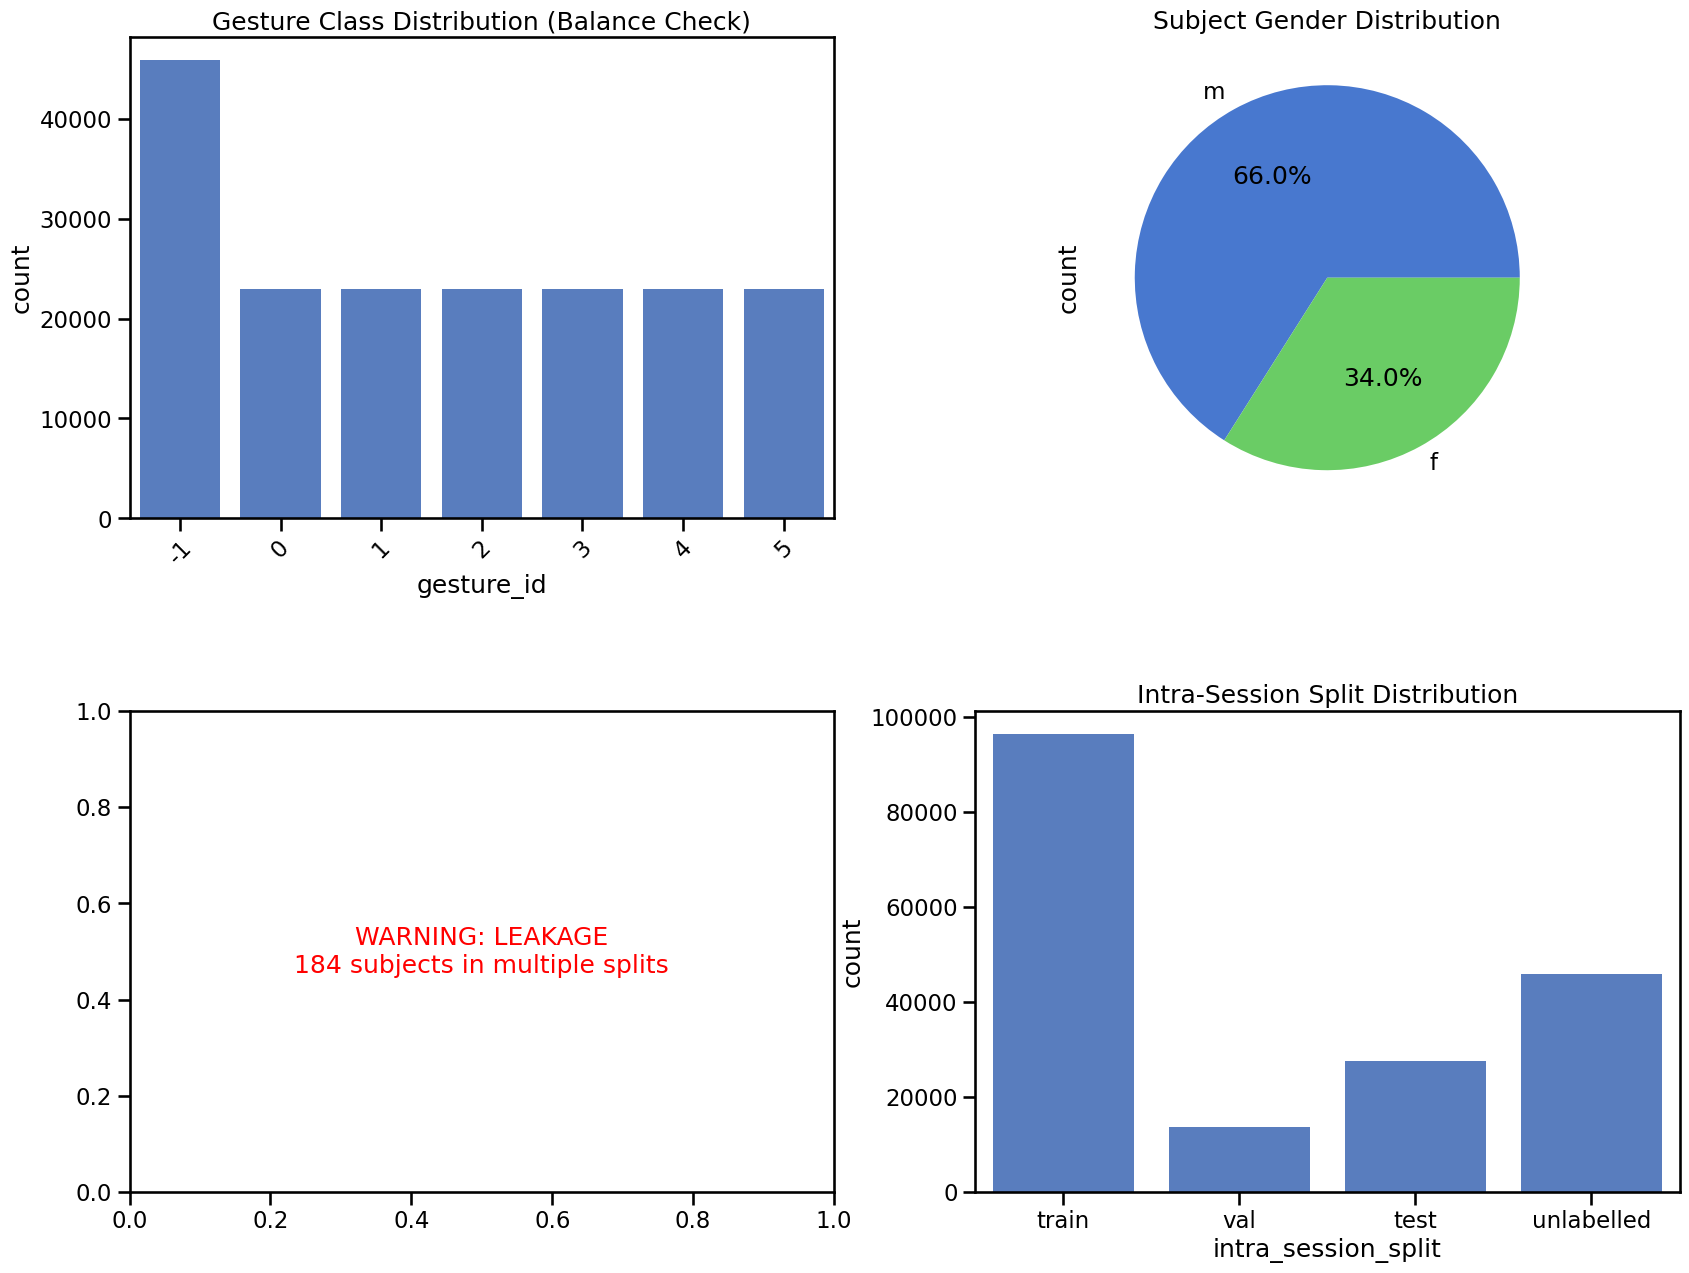

------------------------------
DATASHEET SUMMARY
------------------------------
Total Subjects: 306
Total Trials: 183600
Total EMG Hours: 253.45 hrs
Avg Trial Duration: 4.97s

Ethnicity Breakdown:
ethnicity
latin     305
native      1
Name: count, dtype: int64


In [15]:
df_audit = perform_emg_audit("data/epn612/epn612.hdf5", root_key="epn612")

In [16]:
import h5py
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm

def analyze_class_length_distribution(hdf5_path, root_key):
    """
    Generic analyzer for the Unified Biosignal HDF5 format.
    Focuses on identifying potential label leakage through signal length distribution.
    
    Args:
        hdf5_path (str): Path to the .hdf5 file.
        root_key (str): The root group name (e.g., 'epn612' or 'ninapro_db5').
    """
    data = []
    
    with h5py.File(hdf5_path, 'r') as f:
        if root_key not in f:
            print(f"Error: Root key '{root_key}' not found in {hdf5_path}")
            return
            
        root = f[root_key]
        
        # Crawl subjects
        for subj_id in tqdm(root.keys(), desc="Extracting trial lengths"):
            subj_group = root[subj_id]
            
            # Crawl sessions/trials
            for sess_id in subj_group.keys():
                if not isinstance(subj_group[sess_id], h5py.Group):
                    continue
                
                sess_group = subj_group[sess_id]
                
                # Ensure emg dataset exists
                if 'emg' not in sess_group:
                    continue
                    
                # Extract metadata
                gesture_id = sess_group.attrs.get('gesture_id', -1)
                sample_rate = sess_group.attrs.get('sample_rate', 200)
                
                # Get length T from shape (T, C)
                length_samples = sess_group['emg'].shape[0]
                duration_sec = length_samples / sample_rate
                
                data.append({
                    'subject_id': subj_id,
                    'gesture_id': gesture_id,
                    'length_samples': length_samples,
                    'duration_sec': duration_sec
                })

    df = pd.DataFrame(data)
    
    if df.empty:
        print("No trials found to analyze.")
        return

    # --- Plotting ---
    plt.figure(figsize=(16, 8))
    
    # Sort by gesture_id for readability
    df = df.sort_values('gesture_id')
    
    # We use a boxenplot or boxplot to show the distribution
    sns.boxplot(data=df, x='gesture_id', y='duration_sec', palette='husl')
    
    # Add a horizontal line for the mean duration to highlight outliers
    plt.axhline(df['duration_sec'].mean(), color='red', linestyle='--', alpha=0.6, label='Global Mean')
    
    plt.title(f"Signal Length Distribution per Class: {root_key.upper()}", fontsize=16)
    plt.xlabel("Gesture ID", fontsize=12)
    plt.ylabel("Duration (seconds)", fontsize=12)
    plt.legend()
    plt.grid(axis='y', linestyle=':', alpha=0.7)
    
    # If there are many classes (e.g., EPN612), thin out the x-labels
    if df['gesture_id'].nunique() > 20:
        plt.xticks(rotation=90, fontsize=8)
    
    plt.tight_layout()
    plt.show()

    # --- Statistical Leakage Check ---
    # Calculate variance of lengths per class
    stats = df.groupby('gesture_id')['duration_sec'].agg(['mean', 'std', 'count'])
    print("\n--- Length Statistics per Class ---")
    print(stats.head(10)) # Print first 10 for brevity
    
    # Check if any class is perfectly predictable by length (std == 0)
    leakage_candidates = stats[stats['std'] < 0.001]
    if not leakage_candidates.empty:
        print("\n⚠️ WARNING: Potential Label Leakage Detected!")
        print("The following classes have zero or near-zero variation in length.")
        print("A model could simply learn the sequence length to identify these classes:")
        print(leakage_candidates.index.tolist())
    else:
        print("\n✅ Clean: No classes have a unique, fixed length signature.")

Extracting trial lengths: 100%|██████████| 10/10 [00:00<00:00, 35.01it/s]
/tmp/ipykernel_4016/3475271319.py:69: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='gesture_id', y='duration_sec', palette='husl')


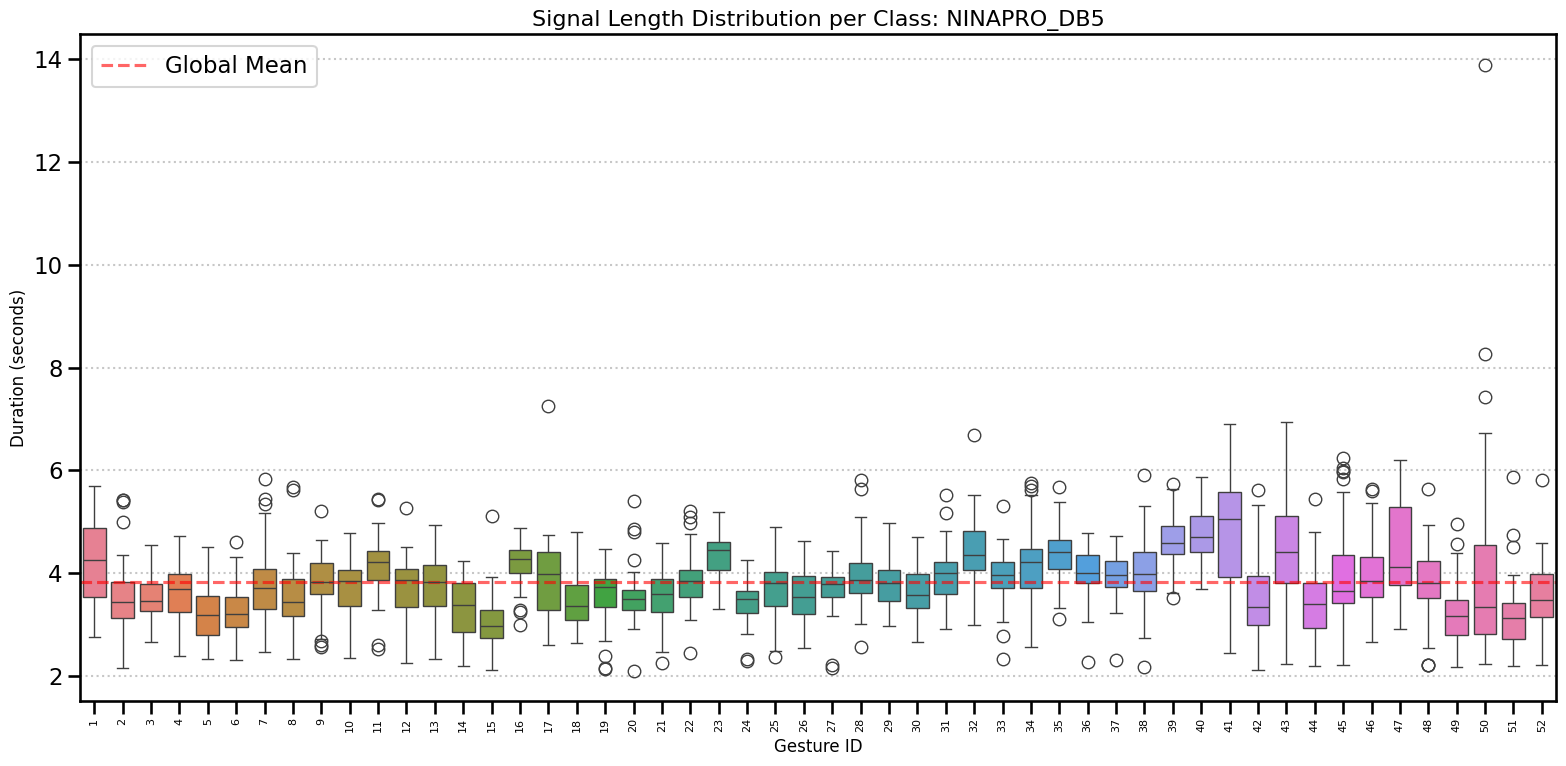


--- Length Statistics per Class ---
                mean       std  count
gesture_id                           
1           4.221917  0.818598     60
2           3.540167  0.695945     60
3           3.564167  0.461686     60
4           3.625917  0.485369     60
5           3.196250  0.499138     60
6           3.262333  0.478385     60
7           3.724667  0.712339     60
8           3.518750  0.621671     60
9           3.849000  0.506393     60
10          3.650583  0.602811     60

✅ Clean: No classes have a unique, fixed length signature.


In [17]:
analyze_class_length_distribution("data/ninapro_db5/ninapro_db5.hdf5", root_key="ninapro_db5")